In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import rc

In [9]:
df1 = pd.read_csv("globular_clusters.csv")
df1 = df1[0:-3]
harris_p1 = pd.read_csv('HarrisPartI.csv')
harris_p2 = pd.read_csv('HarrisPartII.csv')
harris_p3 = pd.read_csv('HarrisPartIII.csv')


In [10]:
rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
rc('text', usetex=True)
R_gc = pd.to_numeric(harris_p1['R_gc'],errors='coerce')
name = harris_p1['ID']
X = pd.to_numeric(harris_p1['X'],errors='coerce')
Y = pd.to_numeric(harris_p1['Y'],errors='coerce')
Z = pd.to_numeric(harris_p1['Z'],errors='coerce')
R_Sun = pd.to_numeric(harris_p1['R_Sun'],errors='coerce')
sig_v = pd.to_numeric(harris_p3['sig_v'],errors='coerce')
v_r = pd.to_numeric(harris_p3['v_r'],errors='coerce')
mtlc = pd.to_numeric(harris_p2['[Fe/H]'],errors='coerce')
rho_0 = pd.to_numeric(harris_p3['rho_0'],errors='coerce')
mu_V = pd.to_numeric(harris_p3['mu_V'],errors='coerce')
c = pd.to_numeric(harris_p3['c'],errors='coerce')
BmV = pd.to_numeric(harris_p2['B-V'],errors='coerce')
ellip = pd.to_numeric(harris_p2['ellip'],errors='coerce')
r_c = pd.to_numeric(harris_p3['r_c'],errors='coerce')
r_h = pd.to_numeric(harris_p3['r_h'],errors='coerce')
M_V = pd.to_numeric(harris_p2['M_V,t'],errors='coerce')
V_t = pd.to_numeric(harris_p2['V_t'],errors='coerce')
wt = pd.to_numeric(harris_p2['wt'],errors='coerce')
L = pd.to_numeric(harris_p1['L'],errors='coerce')
B = pd.to_numeric(harris_p1['B'],errors='coerce')
v_LSR = pd.to_numeric(harris_p3['v_LSR'],errors='coerce')
c_rt = pd.to_numeric(harris_p3['lg_th'],errors='coerce')
m_rt = pd.to_numeric(harris_p3['lg_tc'],errors='coerce')
mask = mtlc > -0.8

In [11]:
X_gc = X-8
Y_gc = Y
Z_gc = Z

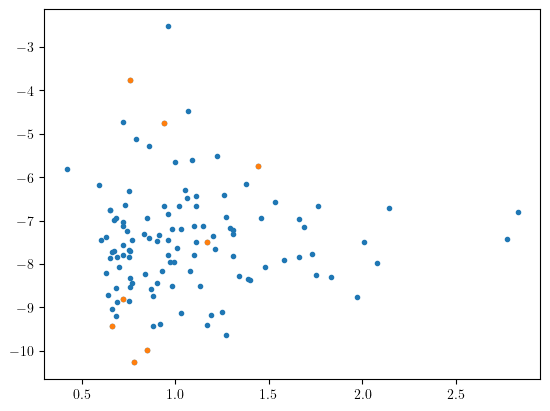

In [12]:
AcGB = [12,28,37,39,45,78,132,133,105,155]

plt.figure()
plt.plot(BmV,M_V,'.')
plt.plot(BmV[AcGB],M_V[AcGB],'.')
plt.show()

In [18]:
V_hb = pd.to_numeric(harris_p2['V_HB'],errors='coerce')
mask = np.isfinite(V_hb) & np.isfinite(mtlc)

In [22]:
from scipy.optimize import curve_fit
def f(x,A,B):
    return A*x+B


y = V_hb[mask]
x = mtlc[mask]

P,C = curve_fit(f,x,y)
Delta = y - f(x,*P)
S_Delta = np.sqrt(1/(len(mask)-2)*np.sum(Delta**2))
xfit = np.linspace(x.min(),x.max(),1000)
sig_fit = np.sqrt(C[0,0]*xfit**2+C[1,1]+2*C[0,1]*xfit)
sig_pred = np.sqrt(sig_fit**2+S_Delta**2)
yfit = f(xfit,*P)
lower2 = yfit-1.96*sig_pred
upper2 = yfit+1.96*sig_pred
lower3 = yfit-3/2*1.96*sig_pred
upper3 = yfit+3/2*1.96*sig_pred
z = abs(Delta/S_Delta)

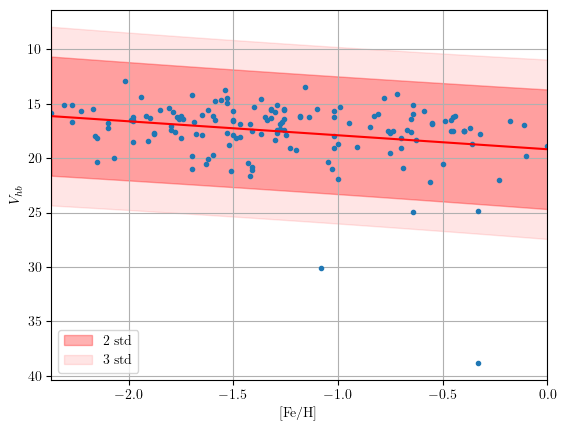

In [24]:
plt.figure()
plt.grid()
plt.plot(x,y,'.')
plt.plot(xfit,yfit,color='red')
plt.fill_between(xfit, lower2, upper2,
                 color='red', alpha=0.3,
                 label=r'$2$ std')
plt.fill_between(xfit, lower3, upper3,
                 color='red', alpha=0.1,
                 label=r'$3$ std')
plt.ylabel(r'$V_{hb}$')
plt.xlabel(r'[Fe/H]')
plt.xlim(xfit[0],xfit[-1])
plt.gca().invert_yaxis()
plt.legend()
plt.show()

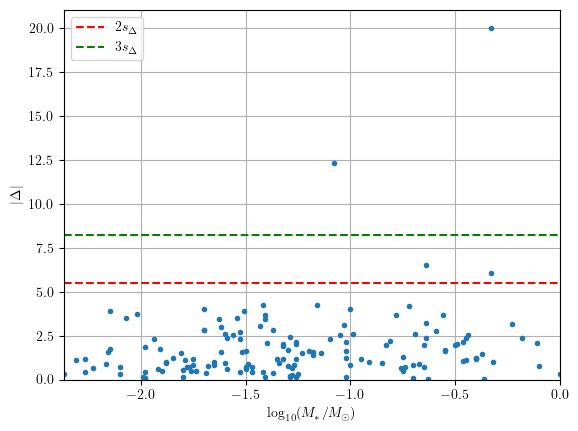

In [25]:
plt.figure()
# plt.plot(Mlog,abs(zp),'.')
plt.plot(x,abs(Delta),'.')
plt.plot(xfit,xfit*0+2*S_Delta,'--',color='red',label=r'$2s_\Delta$')
plt.plot(xfit,xfit*0+3*S_Delta,'--',color='green',label=r'$3s_\Delta$')
plt.xlim(x.min(),x.max())
plt.xlabel(r'$\log_{10}(M_*/M_\odot)$')
plt.ylabel(r'$|\Delta|$')
plt.ylim(0)
plt.grid()
plt.legend()
plt.show()

In [26]:
print(name[mask][z > 3])

114     2MS-GC02
120    GLIMPSE02
Name: ID, dtype: object
